# CLIP on AwA2 — Visualization and Error Analysis

This notebook analyzes the zero-shot classification behavior of CLIP on the **Animals with Attributes 2 (AwA2)** dataset.

The evaluation uses a shared subset of **5,000 images**, consisting of 100 images from each of the 50 animal classes.

The notebook focuses on dataset exploration, class-attribute similarities, classification performance, confusion patterns, and visual inspection of misclassified images.

CLIP predictions are generated separately during Phase I inference and imported into this notebook for analysis.

All class-based analyses use the original AwA2 class order defined in `classes.txt`. Prediction labels are aligned to this order before evaluation.

| # | Section | What it produces |
|---|---|---|
| 1 | Setup | Imports, configuration, and local dataset availability checks |
| 2 | Data loading and label alignment | Class names, evaluation manifest, image validation, and label integrity checks |
| 3 | Dataset exploration | Class distribution and one sample image per class |
| 4 | Attribute similarity | 50 × 50 cosine similarity matrix, heatmap, and most similar class pairs |
| 5 | Predictions | CLIP predictions loaded, aligned, and validated |
| 6 | Error analysis | Confusion matrix, per-class accuracy, and most confused pairs |
| 7 | Confusion vs. attribute similarity | Scatter plot, Spearman correlation, and permutation test |
| 8 | Misclassification gallery | Example images for the most frequent classification error pairs |
| 9 | Conclusion | Summary of CLIP performance, attribute similarity findings, and error analysis |


### Research Questions

This analysis addresses two research questions:

**RQ1:** Which animal classes does CLIP confuse most frequently?

**RQ2:** Are animals with more shared visual attributes more likely to be misclassified as each other?


## 1. Setup

### 1.1 Imports and configuration


In [23]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from scipy.stats import spearmanr
from sklearn.metrics import confusion_matrix


PROJECT_DIR = Path.cwd()

META_DIR = PROJECT_DIR / "metadata"
DATA_DIR = PROJECT_DIR / "data" / "JPEGImages"
PHASE1_DIR = PROJECT_DIR / "phase1_outputs"
IMAGE_ROOT = DATA_DIR

MANIFEST_CSV = PROJECT_DIR / "awa2_subset_5000.csv"

PREDICTIONS_CSV = PHASE1_DIR / "predictions.csv"
CLASS_ORDER_CSV = PHASE1_DIR / "class_order.csv"

GALLERY_N = 12
BAR_COLOR = "#6499F0"
RESULTS_LABEL = "CLIP"

print("Project directory:", PROJECT_DIR)

Project directory: /Users/maielyamani/CLIP_AwA2_Project


### 1.2 Dataset availability
Verify that the required dataset files, metadata, and CLIP prediction files are available in the local project directory.

In [2]:
print("Manifest exists:", MANIFEST_CSV.exists())

print("Classes metadata exists:",
      (META_DIR / "classes.txt").exists())

print("Attribute metadata exists:",
      (META_DIR / "predicate-matrix-binary.txt").exists())

print("Images directory exists:", DATA_DIR.exists())
print("Predictions exist:", PREDICTIONS_CSV.exists())
print("Class order exists:", CLASS_ORDER_CSV.exists())

if DATA_DIR.exists():
    images = list(DATA_DIR.rglob("*.jpg"))
    print("JPEG images found:", len(images))

Manifest exists: True
Classes metadata exists: True
Attribute metadata exists: True
Images directory exists: True
Predictions exist: True
Class order exists: True
JPEG images found: 5000


## 2. Data loading and label alignment

### 2.1 Class names
The original AwA2 class order is defined in `classes.txt` and loaded from the Phase I `class_order.csv` file. This ordering is used consistently for attribute analysis and classification evaluation.

For visualization, `+` characters in class names are replaced with spaces.

In [3]:
class_order = pd.read_csv(CLASS_ORDER_CSV).sort_values("idx")

N_CLASSES = len(class_order)

assert N_CLASSES == 50
assert class_order["idx"].tolist() == list(range(50))

class_names_raw = class_order["class_name"].tolist()

class_names = [
    name.replace("+", " ")
    for name in class_names_raw
]

class_to_id = {
    name: idx
    for idx, name in enumerate(class_names_raw)
}

print("Number of classes:", N_CLASSES)
print("First five:", class_names[:5])

Number of classes: 50
First five: ['antelope', 'grizzly bear', 'killer whale', 'beaver', 'dalmatian']


### 2.2 Load the evaluation manifest

Load the shared `awa2_subset_5000.csv` manifest, containing 5,000 images (100 per class across 50 AwA2 classes).

The manifest provides the relative image paths (`image_path`) and ground-truth class names (`true_label`). Image paths are checked for uniqueness.


In [4]:
manifest = pd.read_csv(MANIFEST_CSV)

assert len(manifest) == 5000
assert manifest["image_path"].is_unique

print(manifest.shape)
display(manifest.head())

(5000, 2)


,image_path,true_label
0,antelope/antelope_10014.jpg,antelope
1,antelope/antelope_10024.jpg,antelope
2,antelope/antelope_10052.jpg,antelope
3,antelope/antelope_10055.jpg,antelope
4,antelope/antelope_10062.jpg,antelope


### 2.3 Validate image availability

Verify that all 5,000 images referenced in the evaluation manifest exist in the local `data/JPEGImages/` directory.


In [5]:
missing_images = [
    path for path in manifest["image_path"]
    if not (DATA_DIR / path).is_file()
]

print("Manifest images:", len(manifest))
print("Missing images:", len(missing_images))

assert len(missing_images) == 0, "Some manifest images are missing!"

Manifest images: 5000
Missing images: 0



### 2.4 Label alignment and integrity checks

Verify that the class ordering matches the original AwA2 `classes.txt` file and is consistent with the attribute matrix.

Validate that all ground-truth labels belong to the 50 AwA2 classes and that each class contains exactly 100 sampled images.

In [6]:
with open(META_DIR / "classes.txt") as f:
    awa2_names = [
        line.split()[-1]
        for line in f if line.strip()
    ]

assert awa2_names == class_names_raw, (
    "CLIP class order and attribute-matrix order differ"
)

print("Class ordering verified!")

Class ordering verified!


In [7]:
assert manifest["true_label"].isin(class_names_raw).all()
assert manifest["true_label"].value_counts().eq(100).all()

print("Images:", len(manifest))
print("Classes:", manifest["true_label"].nunique())
print("Balanced sample verified!")

Images: 5000
Classes: 50
Balanced sample verified!


## 3. Dataset exploration

### 3.1 Class distribution

Visualize the class distribution of the evaluation subset to confirm balanced sampling (100 images per class across 50 classes).

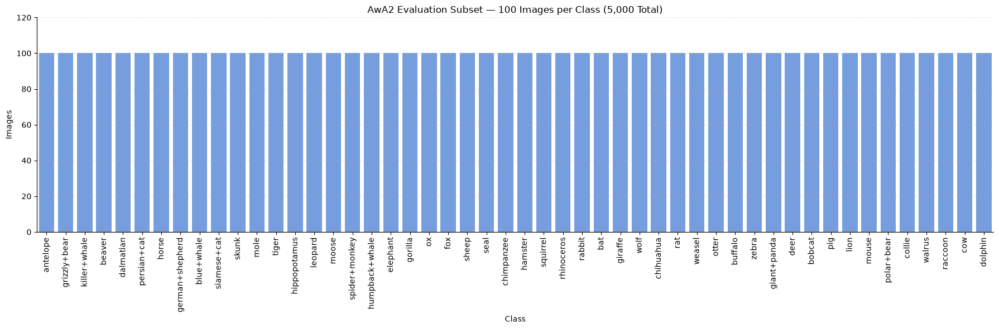

Images per class: min = 100 | max = 100


In [8]:
class_counts = (
    manifest["true_label"]
    .value_counts()
    .reindex(class_names_raw)
)

fig, ax = plt.subplots(figsize=(18, 6))
sns.barplot(x=class_counts.index, y=class_counts.values, color=BAR_COLOR, ax=ax)

ax.set_title("AwA2 Evaluation Subset — 100 Images per Class (5,000 Total)")
ax.set_xlabel("Class")
ax.set_ylabel("Images")
ax.set_ylim(0, class_counts.max() * 1.2)
plt.xticks(rotation=90)
ax.grid(axis="y", linestyle="--", alpha=0.3)
sns.despine()
plt.tight_layout()
plt.show()

print("Images per class: min =", class_counts.min(), "| max =", class_counts.max())

### 3.2 One sample image per class

Display one sample image from each of the 50 AwA2 classes, using the image paths in the shared evaluation manifest.

Each image is shown with its ground-truth class label to visually inspect the dataset and verify image-label correspondence.

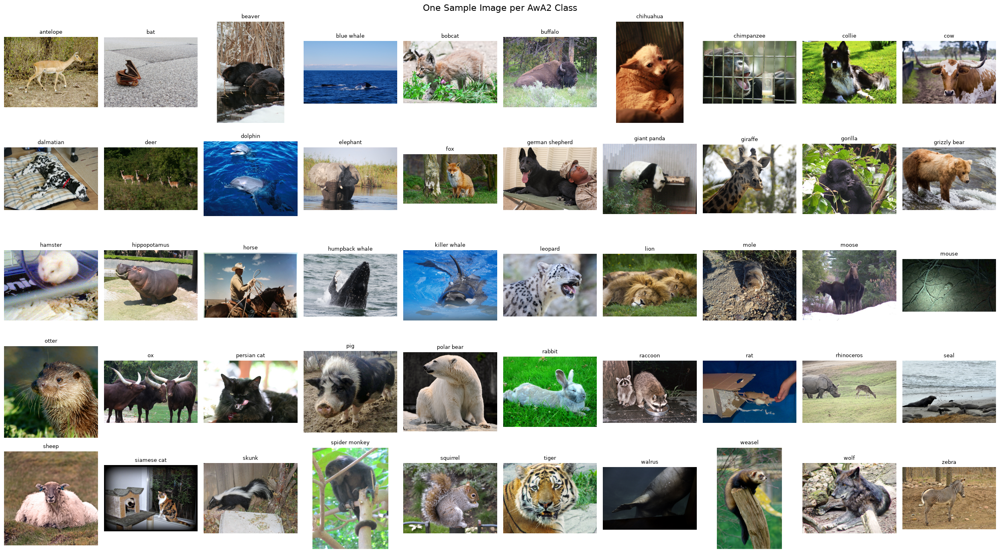

In [9]:
# Select one image from each animal class
picks = (
    manifest.groupby("true_label")
    .head(1)
    .sort_values("true_label")
    .reset_index(drop=True)
)

# Display one representative image per class
fig, axes = plt.subplots(5, 10, figsize=(25, 14), squeeze=False)

for ax in axes.ravel():
    ax.axis("off")

for i, row in picks.iterrows():
    image_path = DATA_DIR / row["image_path"]

    with Image.open(image_path) as img:
        image = img.convert("RGB")

    axes.ravel()[i].imshow(image)
    axes.ravel()[i].set_title(
        row["true_label"].replace("+", " "),
        fontsize=9
    )

fig.suptitle("One Sample Image per AwA2 Class", fontsize=16)
plt.tight_layout()
plt.show()

## 4. Attribute similarity

AwA2 provides 85 class-level attributes for its 50 animal classes. We use the binary class-attribute matrix from `metadata/predicate-matrix-binary.txt`, with rows following the original class order defined in `classes.txt`.

### 4.1 Attribute matrix

In [10]:
attributes = np.loadtxt(META_DIR / "predicate-matrix-binary.txt")

print("Shape:", attributes.shape)                 # (50, 85)
print("Unique values:", np.unique(attributes))    # [0. 1.]
assert np.isin(attributes, [0, 1]).all()
assert attributes.shape == (N_CLASSES, 85)
assert (attributes.sum(axis=1) > 0).all(), "A class has no attributes, so cosine similarity is undefined"

Shape: (50, 85)
Unique values: [0. 1.]


### 4.2 Cosine similarity between classes

Cosine similarity between two class-attribute vectors *A* and *B* is calculated as:

$$
\text{sim}(A,B) = \frac{A \cdot B}{\|A\| \|B\|}
$$

The normalized attribute matrix is used to compute pairwise similarities for all 50 classes, producing a 50 × 50 symmetric matrix.


In [11]:
norms = np.linalg.norm(attributes, axis=1, keepdims=True)
normalized = attributes / norms
similarity = normalized @ normalized.T

off_diag = ~np.eye(N_CLASSES, dtype=bool)
print("Similarity shape:", similarity.shape)
print("Diagonal all 1:", np.allclose(np.diag(similarity), 1.0))
print("Off-diagonal range:", similarity[off_diag].min().round(2), "to", similarity[off_diag].max().round(2))
assert np.allclose(similarity, similarity.T)

Similarity shape: (50, 50)
Diagonal all 1: True
Off-diagonal range: 0.14 to 0.93


### 4.3 Similarity heatmap

Visualize the 50 × 50 cosine similarity matrix as a heatmap. Brighter cells indicate higher attribute similarity, while the diagonal represents self-similarity.

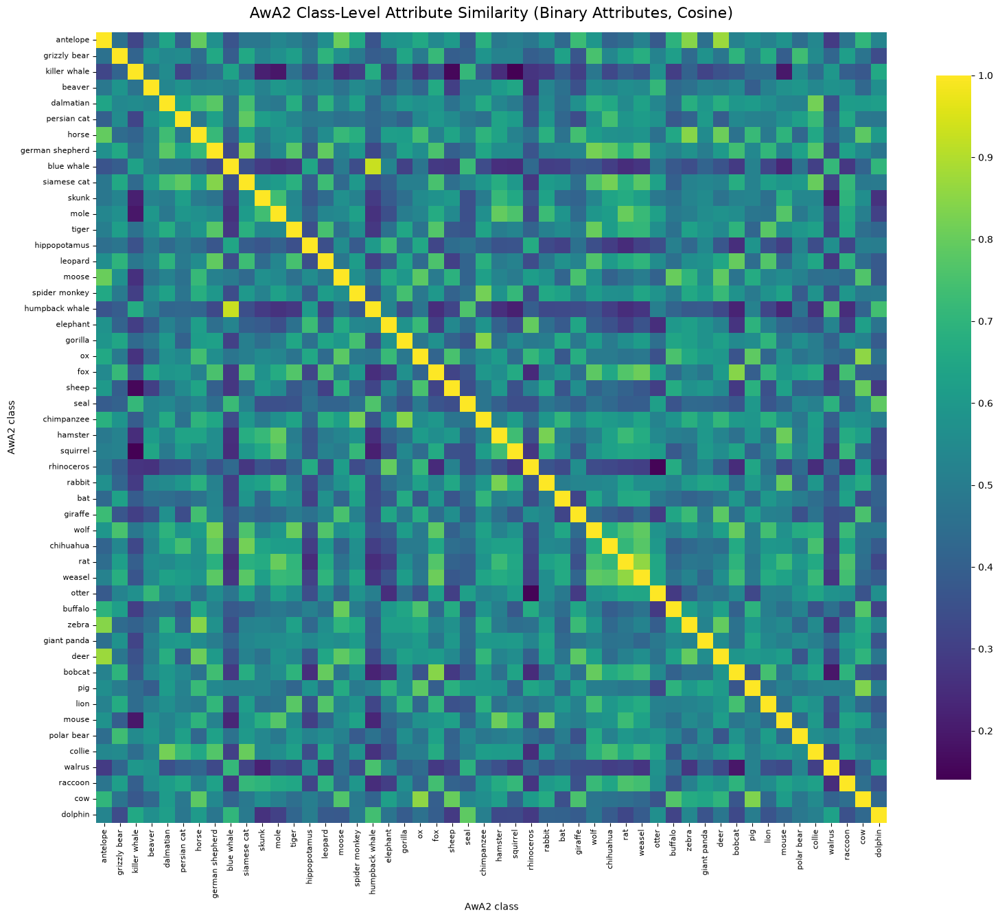

In [12]:
fig, ax = plt.subplots(figsize=(16, 14))
sns.heatmap(
    similarity,
    xticklabels=class_names,
    yticklabels=class_names,
    cmap="viridis",
    square=True,
    annot=False,                  # 2,500 numbers would be unreadable
    cbar_kws={"shrink": 0.8},
    ax=ax,
)

ax.set_title(
    "AwA2 Class-Level Attribute Similarity (Binary Attributes, Cosine)",
    fontsize=16,
    pad=15
)
ax.set_xlabel("AwA2 class")
ax.set_ylabel("AwA2 class")
plt.xticks(rotation=90, fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()

### 4.4 Most similar class pairs

Identify the class pairs with the highest cosine similarity based on their annotated attributes, excluding self-similarity. This analysis is independent of CLIP predictions.

In [13]:
sim_df = pd.DataFrame(similarity, index=class_names, columns=class_names)

top_similar = (
    sim_df.where(np.triu(np.ones(sim_df.shape, dtype=bool), k=1))   # upper triangle: each pair once
          .stack()
          .sort_values(ascending=False)
          .head(10)
)
top_similar.index.names = ["class_a", "class_b"]
display(top_similar.rename("cosine_similarity").round(3).reset_index())

,class_a,class_b,cosine_similarity
0,blue whale,humpback whale,0.929
1,antelope,deer,0.871
2,rat,weasel,0.856
3,ox,cow,0.853
4,horse,zebra,0.845
5,fox,bobcat,0.845
6,gorilla,chimpanzee,0.845
7,antelope,zebra,0.843
8,german shepherd,siamese cat,0.841
9,pig,cow,0.833


## 5. Predictions

Load the CLIP zero-shot predictions and merge them with the 5,000-image evaluation manifest using `image_path`.

Validate prediction coverage, label consistency, and alignment with the original AwA2 class order. Recompute prediction correctness and calculate overall accuracy and the number of misclassifications.

The top-1 and top-2 similarity scores are retained for error analysis.

In [14]:
real = pd.read_csv(PREDICTIONS_CSV)

assert len(real) == 5000
assert real["image_path"].is_unique

predictions = manifest.merge(
    real,
    on="image_path",
    how="left",
    validate="one_to_one",
    suffixes=("_manifest", "")
)

assert len(predictions) == len(manifest) == 5000
assert predictions["predicted_label"].notna().all()

assert (
    predictions["true_label_manifest"]
    == predictions["true_label"]
).all()

predictions["true_label_id"] = (
    predictions["true_label"].map(class_to_id)
)

predictions["pred_label"] = (
    predictions["predicted_label"].map(class_to_id)
)

assert predictions["true_label_id"].notna().all()
assert predictions["pred_label"].notna().all()

accuracy = (
    predictions["true_label_id"]
    == predictions["pred_label"]
).mean()

assert (
    predictions["correct"].astype(bool)
    == (predictions["true_label_id"] == predictions["pred_label"])
).all()

print(f"CLIP accuracy: {accuracy:.2%}")
n_errors = (predictions["true_label_id"] != predictions["pred_label"]).sum()

print("Number of errors:", n_errors)

display(predictions.head())

CLIP accuracy: 92.08%
Number of errors: 396


,image_path,true_label_manifest,true_label,predicted_label,correct,top1_similarity,top2_label,top2_similarity,margin,true_label_similarity,true_label_rank,top5_labels,width,height,orig_mode,true_label_id,pred_label
0,antelope/antelope_10014.jpg,antelope,antelope,antelope,True,0.305592,deer,0.287386,0.018206,0.305592,1,antelope|deer|giraffe|zebra|weasel,1024,768,RGB,0,0
1,antelope/antelope_10024.jpg,antelope,antelope,antelope,True,0.284234,deer,0.244064,0.040170,0.284234,1,antelope|deer|giraffe|horse|zebra,1024,683,RGB,0,0
2,antelope/antelope_10052.jpg,antelope,antelope,antelope,True,0.316489,deer,0.266815,0.049674,0.316489,1,antelope|deer|giraffe|zebra|horse,1024,683,RGB,0,0
3,antelope/antelope_10055.jpg,antelope,antelope,antelope,True,0.308152,deer,0.263010,0.045142,0.308152,1,antelope|deer|zebra|giraffe|lion,1024,768,RGB,0,0
4,antelope/antelope_10062.jpg,antelope,antelope,antelope,True,0.298666,deer,0.248639,0.050027,0.298666,1,antelope|deer|siamese+cat|horse|weasel,500,333,RGB,0,0


## 6. Error analysis

**RQ1:** Which animal classes does CLIP confuse most frequently?

### 6.1 Confusion matrix

Visualize the row-normalized confusion matrix, with true classes as rows and predicted classes as columns.

Diagonal values represent per-class accuracy, while off-diagonal values indicate the proportion of images misclassified into other classes.

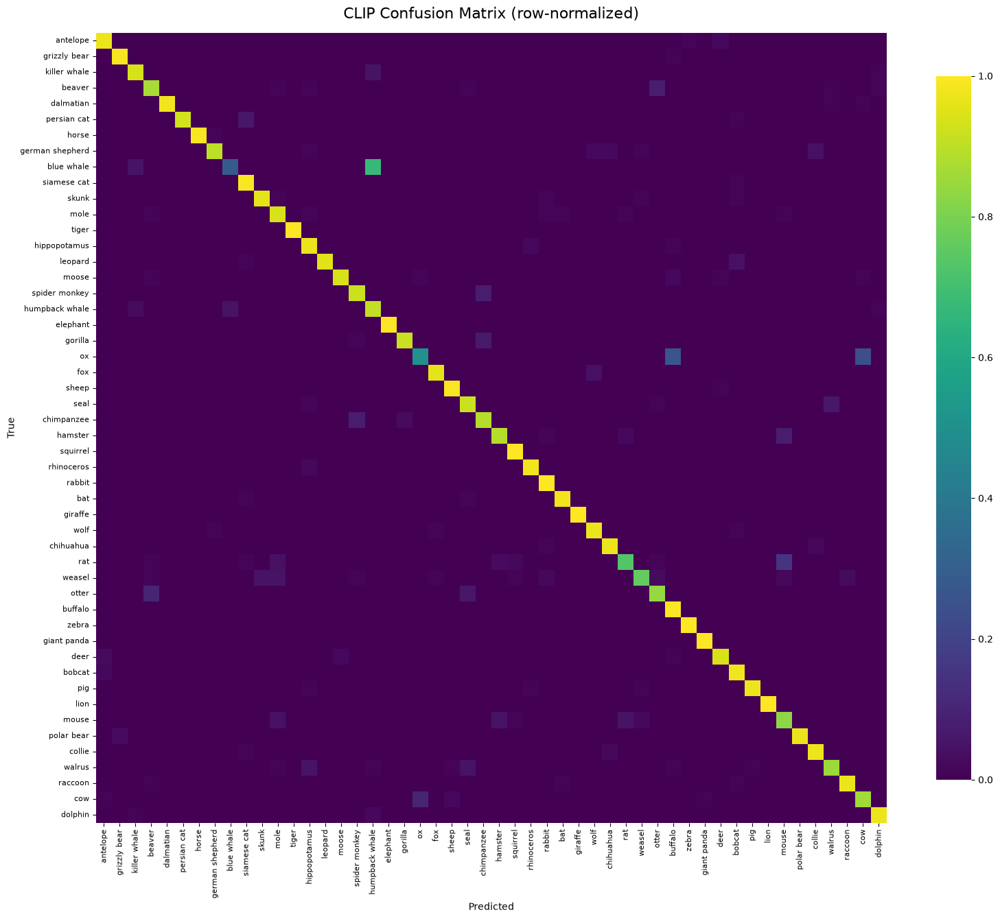

In [15]:
y_true = predictions["true_label_id"].to_numpy()
y_pred = predictions["pred_label"].to_numpy()

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=range(N_CLASSES)
)

cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(16, 14))
sns.heatmap(cm_norm, xticklabels=class_names, yticklabels=class_names,
            cmap="viridis", square=True, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title(f"{RESULTS_LABEL} Confusion Matrix (row-normalized)", fontsize=16, pad=15)
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
plt.xticks(rotation=90, fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()

### 6.2 Per-class accuracy

Visualize per-class accuracy, sorted from lowest to highest. The dashed line indicates the overall classification accuracy.

10 weakest classes:


,class_name,accuracy
0,blue whale,28.0
1,ox,50.0
2,rat,73.0
3,weasel,76.0
4,mouse,83.0
5,otter,84.0
6,walrus,85.0
7,cow,86.0
8,beaver,87.0
9,hamster,89.0


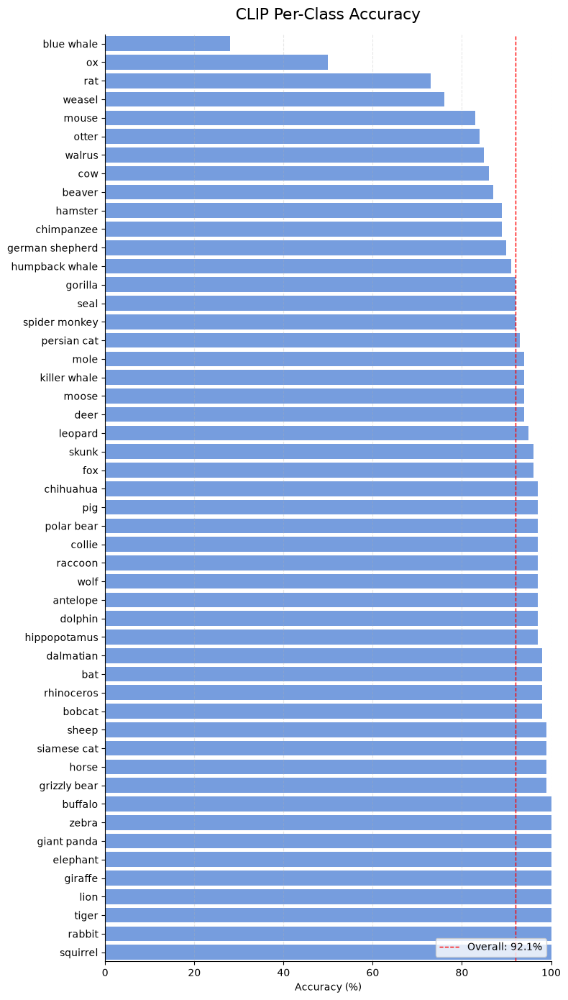

In [16]:
per_class_accuracy = np.diag(cm_norm) * 100
overall_accuracy = np.trace(cm) / cm.sum() * 100

accuracy_df = (
    pd.DataFrame({"class_name": class_names, "accuracy": per_class_accuracy})
    .sort_values("accuracy")
    .reset_index(drop=True)
)

print("10 weakest classes:")
display(accuracy_df.head(10))

fig, ax = plt.subplots(figsize=(8, 14))
sns.barplot(data=accuracy_df, x="accuracy", y="class_name", color=BAR_COLOR, ax=ax)
ax.axvline(overall_accuracy, color="red", linestyle="--", linewidth=1, label=f"Overall: {overall_accuracy:.1f}%")
ax.set_xlim(0, 100)
ax.set_xlabel("Accuracy (%)")
ax.set_ylabel("")
ax.set_title(f"{RESULTS_LABEL} Per-Class Accuracy", fontsize=16, pad=15)
ax.legend(loc="lower right")
ax.grid(axis="x", linestyle="--", alpha=0.3)
sns.despine()
plt.tight_layout()
plt.show()

### 6.3 Most confused class pairs

Rank the most frequent misclassifications by direction (true class → predicted class). Each value represents the percentage of images from the true class incorrectly predicted as the other class.

In [17]:
conf = cm_norm.copy()
np.fill_diagonal(conf, 0)          # ignore correct predictions

top_confused = (
    pd.DataFrame(conf * 100, index=class_names, columns=class_names)
    .stack()
    .sort_values(ascending=False)
    .head(10)
)
top_confused.index.names = ["true_class", "predicted_as"]
display(top_confused.rename("confusion_%").round(1).reset_index())

,true_class,predicted_as,confusion_%
0,blue whale,humpback whale,67.0
1,ox,buffalo,26.0
2,ox,cow,24.0
3,rat,mouse,15.0
4,otter,beaver,10.0
5,cow,ox,10.0
6,hamster,mouse,8.0
7,spider monkey,chimpanzee,8.0
8,beaver,otter,8.0
9,chimpanzee,spider monkey,8.0


### Interpretation of RQ1

CLIP's most frequent misclassifications occur between related animal classes. The most prominent confusion is **blue whale → humpback whale (67 errors)**, followed by **ox → buffalo (26 errors)** and **ox → cow (24 errors)**.

These results suggest that CLIP particularly struggles to distinguish certain visually or semantically similar animal classes, although the frequency of errors varies considerably across class pairs.

## 7. Confusion vs. Attribute Similarity

**RQ2:** Are animals with more shared visual attributes more likely to be misclassified as each other?

We compare the class-level attribute cosine similarity matrix with CLIP's row-normalized confusion matrix, excluding the diagonal to obtain 2,450 directed class pairs.

Since attribute similarity is symmetric but confusion is directional, both directions are analyzed separately. Spearman's rank correlation is used to assess the association, accounting for the highly skewed distribution of confusion rates.

### 7.1 Scatter plot and Spearman correlation

Spearman rho = 0.237, nominal p = 1.54e-32  (see 7.2 for the permutation p-value)


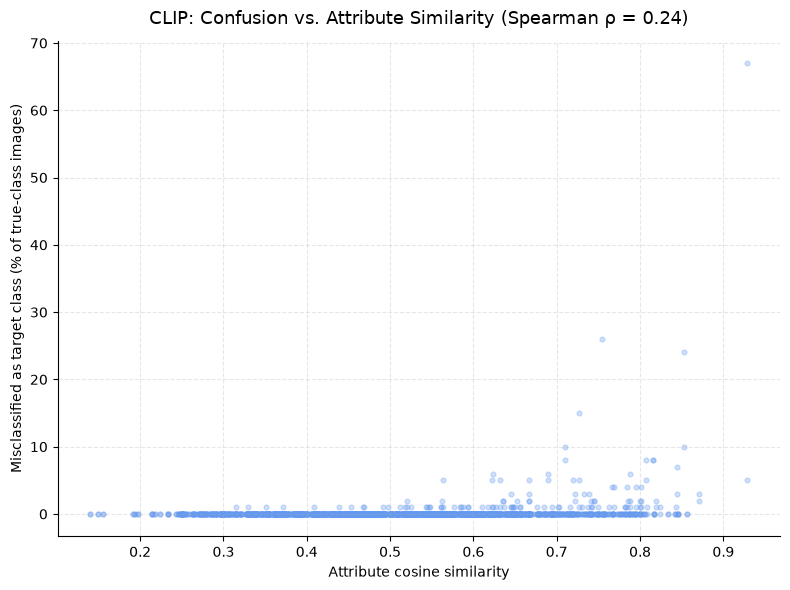

In [18]:
mask = ~np.eye(N_CLASSES, dtype=bool)      # off-diagonal cells only

sim_vals  = similarity[mask]               # attribute cosine similarity
conf_vals = cm_norm[mask] * 100            # % of the true class predicted as the other class

rho, p = spearmanr(sim_vals, conf_vals)
print(f"Spearman rho = {rho:.3f}, nominal p = {p:.3g}  (see 7.2 for the permutation p-value)")

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(sim_vals, conf_vals, alpha=0.3, s=12, color=BAR_COLOR)
ax.set_xlabel("Attribute cosine similarity")
ax.set_ylabel("Misclassified as target class (% of true-class images)")
ax.set_title(f"{RESULTS_LABEL}: Confusion vs. Attribute Similarity (Spearman ρ = {rho:.2f})", fontsize=13, pad=12)
ax.grid(alpha=0.3, linestyle="--")
sns.despine()
plt.tight_layout()
plt.show()

### Interpretation

Spearman's correlation (ρ = 0.237) indicates a weak positive association between attribute similarity and CLIP confusion. However, many highly similar class pairs show no observed confusion, suggesting that attribute similarity alone does not explain classification errors.

Because class pairs are not independent, the nominal Spearman p-value may be unreliable. A class-label permutation test is therefore performed in Section 7.2 to assess statistical significance.

### 7.2 Permutation test

Because class pairs are not independent, we use a class-label permutation test to assess the significance of the observed correlation.

Class labels in the confusion matrix are jointly shuffled across rows and columns for 2,000 permutations. The p-value is calculated as `(k + 1) / (n + 1)`, where `k` is the number of permutations producing a correlation at least as extreme as the observed value and `n = 2,000`.

In [19]:
rng = np.random.default_rng(0)
N_PERM = 2000
obs_rho = spearmanr(sim_vals, conf_vals)[0]

perm_rhos = np.empty(N_PERM)
for k in range(N_PERM):
    perm = rng.permutation(N_CLASSES)
    cm_perm = cm_norm[np.ix_(perm, perm)]      # shuffle class identities
    perm_rhos[k] = spearmanr(sim_vals, cm_perm[mask] * 100)[0]

p_perm = (np.sum(np.abs(perm_rhos) >= abs(obs_rho)) + 1) / (N_PERM + 1)
print(f"Observed rho = {obs_rho:.3f} | permutation p = {p_perm:.4f}  ({N_PERM} permutations)")

Observed rho = 0.237 | permutation p = 0.0005  (2000 permutations)


### Interpretation of the Permutation Test

The observed correlation (ρ = 0.237) is statistically significant (permutation p ≈ 0.0005, 2,000 permutations). None of the permutations produced an absolute correlation as large as the observed value.

This provides evidence against random class-label alignment, although the association remains weak.

### RQ2 Conclusion

Classes with more similar annotated attributes tend to be confused somewhat more frequently by CLIP.

For example, blue whale and humpback whale have high attribute similarity (0.929), with 67% of blue whale images misclassified as humpback whale.

Overall, attribute similarity is significantly associated with CLIP confusion but does not fully explain classification errors. The findings indicate correlation, not causation.

## 8. Misclassification gallery

Visualize representative misclassified images from the `GALLERY_N` most frequent directional error pairs (true → predicted).

Each image is displayed with its ground-truth label, predicted label, and the total number of misclassifications for that pair.

In [20]:
def load_images(rows):
    images = []

    for _, row in rows.iterrows():
        image_path = IMAGE_ROOT / row["image_path"]

        with Image.open(image_path) as img:
            images.append(img.convert("RGB").copy())

    return images

In [21]:
missing = [
    p for p in predictions["image_path"]
    if not (IMAGE_ROOT / p).is_file()
]

print("Missing prediction images:", len(missing))

Missing prediction images: 0


Number of errors: 396


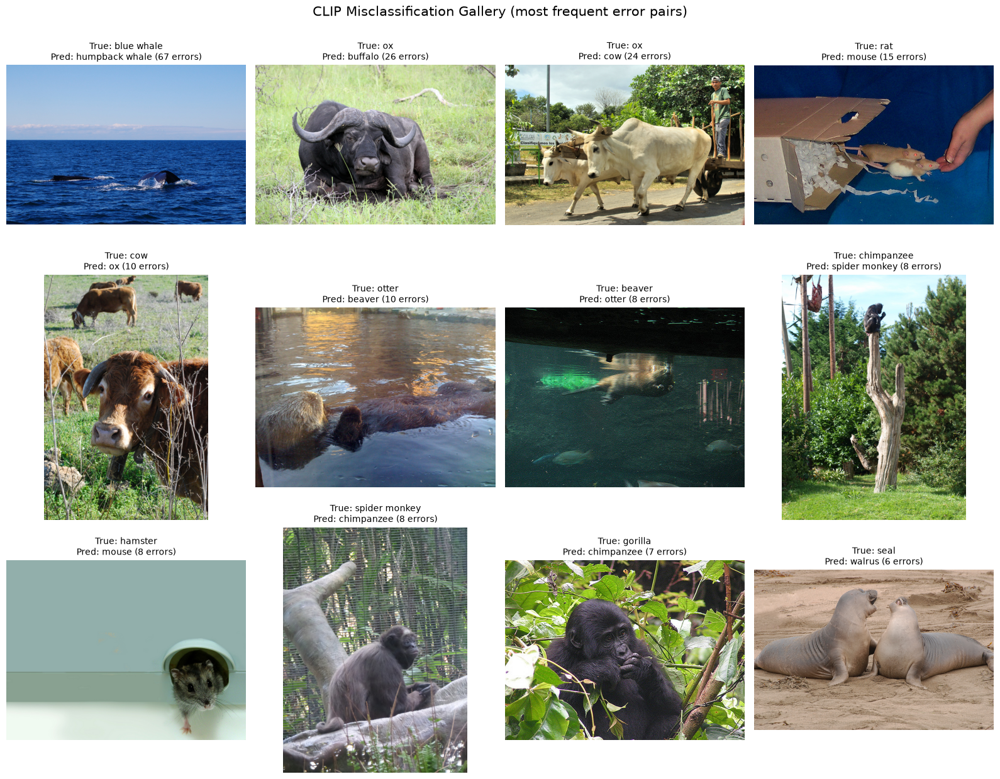

In [24]:
errors = predictions[
    predictions["true_label_id"] != predictions["pred_label"]
].copy()

print("Number of errors:", len(errors))
assert len(errors) == n_errors
assert len(errors) == (~predictions["correct"].astype(bool)).sum()

pair_counts = (
    errors.groupby(["true_label", "pred_label"]).size().rename("n").reset_index()
          .sort_values("n", ascending=False).head(GALLERY_N)
)

gallery = (
    errors.merge(pair_counts, on=["true_label", "pred_label"])
          .groupby(["true_label", "pred_label"]).head(1)       # one example per pair
          .sort_values("n", ascending=False)
          .reset_index(drop=True)
)
gallery_images = load_images(gallery)

ncols = 4
nrows = int(np.ceil(len(gallery) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 4.2 * nrows), squeeze=False)
for ax in axes.ravel():
    ax.axis("off")

for i, r in gallery.iterrows():
    ax = axes.ravel()[i]
    ax.imshow(gallery_images[i])
    ax.set_title(
        f"True: {class_names[int(r['true_label_id'])]}\n"
        f"Pred: {class_names[int(r['pred_label'])]} ({r['n']} errors)",
        fontsize=10
    )

fig.suptitle(f"{RESULTS_LABEL} Misclassification Gallery (most frequent error pairs)", fontsize=15)
plt.tight_layout()
plt.show()

## 9. Conclusion

CLIP achieved **92.08% zero-shot classification accuracy** on the balanced 5,000-image AwA2 evaluation subset, with 396 misclassifications.

The analysis found a statistically significant but weak positive association between class-level attribute similarity and CLIP confusion (Spearman ρ = 0.237, permutation p ≈ 0.0005).

The confusion matrix and misclassification gallery highlight recurring errors between visually or semantically related animal classes. Overall, attribute similarity helps explain some classification errors but is not sufficient to account for CLIP's behavior.